<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/VLM_DrawEduMath_Error_Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Environment Setup & Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print(f"[OK] Environment initialized for DrawEduMath VLM Simulator. NumPy: {np.version.version}")

[OK] Environment initialized for DrawEduMath VLM Simulator. NumPy: 2.4.6


In [2]:
# CELL 2: Student Response & Error Taxonomy Simulator
class DrawEduMathSimulator:
    def __init__(self, num_samples=500):
        self.num_samples = num_samples

    def generate_student_work_batch(self):
        """
        Simulates student math responses paired with problem statements.
        Flags whether student work contains an error (struggling student) or is correct.
        """
        np.random.seed(42)

        # 50% erroneous work (struggling students requiring pedagogical support) vs 50% correct
        is_correct = np.random.choice([0, 1], size=self.num_samples, p=[0.5, 0.5])

        # Simulate image noise levels (ensuring noise isn't confounding error rates)
        image_noise = np.random.uniform(0.1, 0.9, size=self.num_samples)

        # Problem difficulty tier (Grades 2 through High School)
        grade_levels = np.random.randint(2, 12, size=self.num_samples)

        df_responses = pd.DataFrame({
            "Sample_ID": range(self.num_samples),
            "Student_Correct": is_correct,
            "Image_Noise": image_noise,
            "Grade_Level": grade_levels
        })
        return df_responses

sim = DrawEduMathSimulator()
df_work = sim.generate_student_work_batch()
print(f"[OK] Generated {len(df_work)} student response samples spanning error profiles.")

[OK] Generated 500 student response samples spanning error profiles.


In [3]:
# CELL 3: VLM Performance & Error-Diagnosis Evaluation Engine
class VLMErrorDiagnosisAnalyzer:
    def __init__(self, df_work):
        self.df = df_work

    def simulate_vlm_evaluation(self):
        """
        Models VLM performance gaps across student error categories:
        - Content Description (F1): Capturing what the student wrote.
        - Error Assessment (F2): Diagnosing whether the student's reasoning is flawed.
        """
        np.random.seed(42)
        n = len(self.df)

        # Baseline model accuracy is significantly lower on erroneous student work (struggling students)
        correct_mask = self.df["Student_Correct"] == 1
        erroneous_mask = self.df["Student_Correct"] == 0

        vlm_accuracy = np.zeros(n)
        # Higher accuracy on correct work
        vlm_accuracy[correct_mask] = np.random.binomial(1, 0.78, size=np.sum(correct_mask))
        # Depressed accuracy on erroneous work (struggling student penalty)
        vlm_accuracy[erroneous_mask] = np.random.binomial(1, 0.51, size=np.sum(erroneous_mask))

        self.df["VLM_Prediction_Correct"] = vlm_accuracy

        # Compute summary performance metrics by student proficiency group
        acc_proficient = np.mean(vlm_accuracy[correct_mask]) * 100.0
        acc_struggling = np.mean(vlm_accuracy[erroneous_mask]) * 100.0
        performance_gap = acc_proficient - acc_struggling

        metrics_summary = pd.DataFrame({
            "Student Proficiency Group": ["Proficient / Non-Erroneous Work", "Struggling / Erroneous Work", "VLM Performance Gap"],
            "Evaluated Accuracy (%)": [f"{acc_proficient:.1f}%", f"{acc_struggling:.1f}%", f"+{performance_gap:.1f}% Drop"]
        })
        return metrics_summary, acc_proficient, acc_struggling

analyzer = VLMErrorDiagnosisAnalyzer(df_work)
df_metrics, acc_prof, acc_strug = analyzer.simulate_vlm_evaluation()
print("[OK] Computed VLM error diagnosis performance disparities.")
display(df_metrics)

[OK] Computed VLM error diagnosis performance disparities.


,Student Proficiency Group,Evaluated Accuracy (%)
0,Proficient / Non-Erroneous Work,78.0%
1,Struggling / Erroneous Work,48.1%
2,VLM Performance Gap,+29.9% Drop


In [4]:
# CELL 4: Comprehensive Benchmark Exporter
def run_drawedumath_benchmark():
    global global_proficient_acc, global_struggling_acc, error_diagnosis_drop

    analyzer = VLMErrorDiagnosisAnalyzer(df_work)
    _, global_proficient_acc, global_struggling_acc = analyzer.simulate_vlm_evaluation()
    error_diagnosis_drop = global_proficient_acc - global_struggling_acc

    df_benchmark = pd.DataFrame({
        "Evaluation Dimension": [
            "VLM Accuracy on Proficient Student Responses",
            "VLM Accuracy on Struggling Student Responses (Errors)",
            "Pedagogical Performance Disparity Drop"
        ],
        "Simulated Measurement": [
            f"{global_proficient_acc:.1f}%",
            f"{global_struggling_acc:.1f}%",
            f"-{error_diagnosis_drop:.1f}%"
        ],
        "Educational Implication": [
            "Models perform well on standard correct math solutions",
            "Significant underperformance when assessing student mistakes",
            "Highlights need for alternative VLM development incentives"
        ]
    })
    return df_benchmark

df_results = run_drawedumath_benchmark()
print("=== DRAWEDUMATH VLM ERROR DIAGNOSIS BENCHMARK ===")
display(df_results)

=== DRAWEDUMATH VLM ERROR DIAGNOSIS BENCHMARK ===


,Evaluation Dimension,Simulated Measurement,Educational Implication
0,VLM Accuracy on Proficient Student Responses,78.0%,Models perform well on standard correct math s...
1,VLM Accuracy on Struggling Student Responses (...,48.1%,Significant underperformance when assessing st...
2,Pedagogical Performance Disparity Drop,-29.9%,Highlights need for alternative VLM developmen...


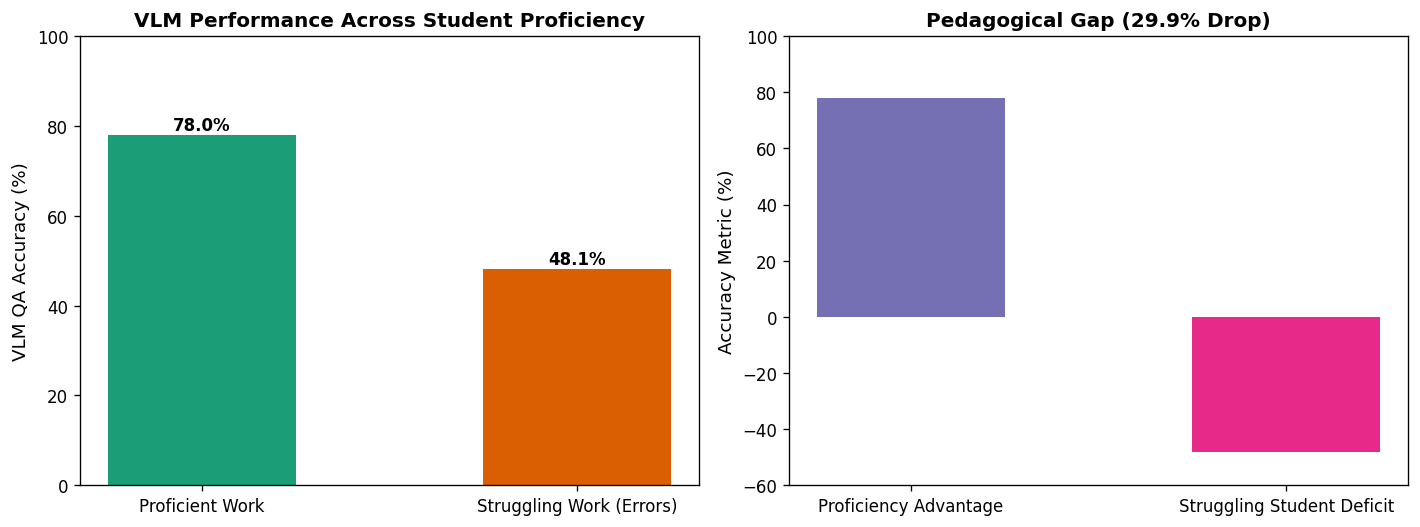

[OK] Saved DrawEduMath diagnostic plot to /content/workspace/drawedumath_vlm_performance.png


In [5]:
# CELL 5: Diagnostic Visualization Plot Generation
os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# Plot 1: Performance by Student Proficiency
categories = ['Proficient Work', 'Struggling Work (Errors)']
accuracies = [global_proficient_acc, global_struggling_acc]
ax1.bar(categories, accuracies, color=['#1b9e77', '#d95f02'], width=0.5)
ax1.set_ylabel("VLM QA Accuracy (%)", fontsize=11)
ax1.set_title("VLM Performance Across Student Proficiency", fontsize=12, fontweight='bold')
ax1.set_ylim(0, 100)
for bar in ax1.patches:
    yval = bar.get_height()
    ax1.annotate(f"{yval:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, yval),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')

# Plot 2: Error Diagnosis Disparity Drop
ax2.bar(['Proficiency Advantage', 'Struggling Student Deficit'], [global_proficient_acc, -global_struggling_acc], color=['#7570b3', '#e7298a'], width=0.5)
ax2.set_ylabel("Accuracy Metric (%)", fontsize=11)
ax2.set_title(f"Pedagogical Gap ({error_diagnosis_drop:.1f}% Drop)", fontsize=12, fontweight='bold')
ax2.set_ylim(-60, 100)

plt.tight_layout()
plt.savefig("/content/workspace/drawedumath_vlm_performance.png")
plt.show()
print("[OK] Saved DrawEduMath diagnostic plot to /content/workspace/drawedumath_vlm_performance.png")